<a href="https://colab.research.google.com/github/2020010003/forest-reservation-analysis/blob/main/%EC%82%B0%EB%A6%BC%EC%B2%AD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== 데이터 기본 정보 ===
총 데이터 건수: 27,192 건
분석 대상 휴양림 수: 47 개
분석 대상 지역 수: 8 개 지역



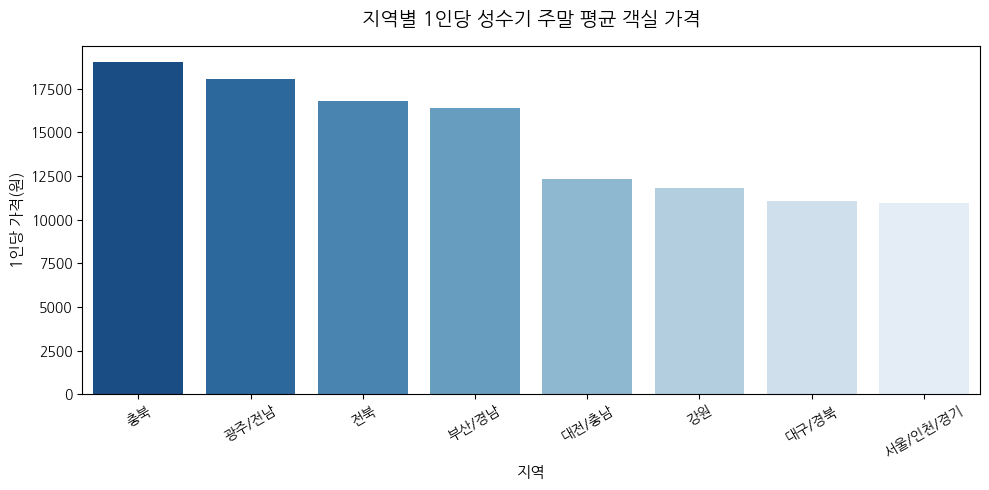

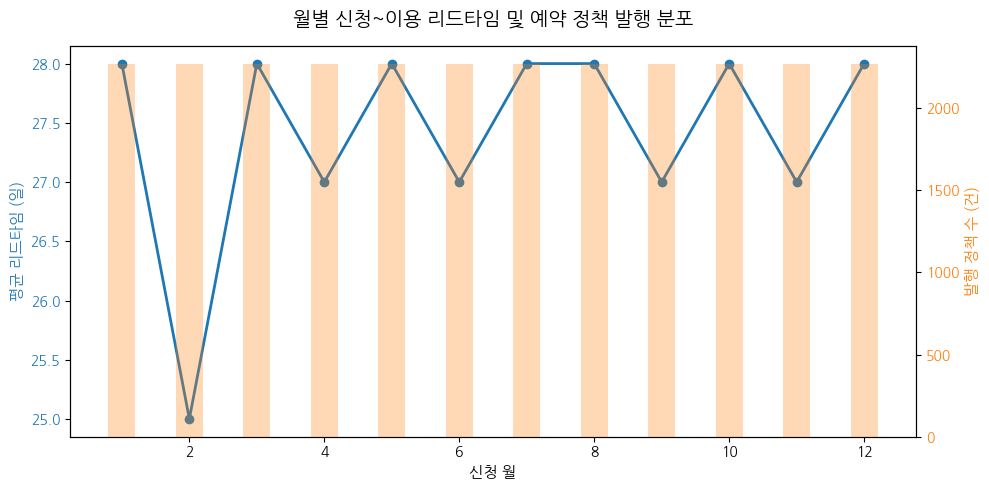

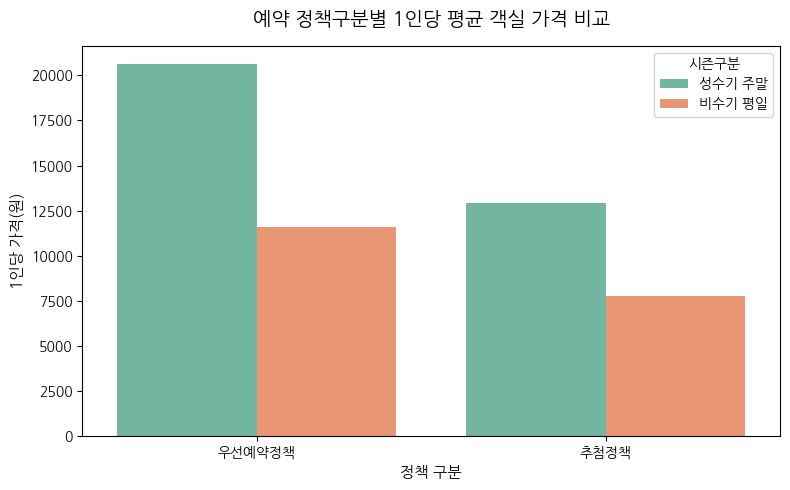


🎉 모든 시각화 이미지(01_region_price.png, 02_leadtime_trend.png, 03_policy_comparison.png) 저장 완료!


In [ ]:
# 1. 한글 폰트 설치 및 폰트 캐시 갱신
!apt-get install -y fonts-nanum > /dev/null

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib as mpl
import pandas as pd
import numpy as np
import seaborn as sns

# 설치된 나눔고딕 폰트 경로 직접 등록 및 캐시 재설정
font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
font_prop = fm.FontProperties(fname=font_path)
fm.fontManager.addfont(font_path)

plt.rc('font', family=font_prop.get_name())
plt.rc('axes', unicode_minus=False)
mpl.rcParams['font.family'] = font_prop.get_name()

# 2. 데이터 불러오기
file_path = "신청기간 - 산림청 국립자연휴양림관리소_국립자연휴양림 우선예약 및 추첨예약 정책_20260126.csv"
df = pd.read_csv(file_path)

# 3. 데이터 전처리 및 시계열 변수 파싱
df['신청시작일'] = pd.to_datetime(df['신청기간'].str.split('~').str[0], errors='coerce')
df['사용시작일'] = pd.to_datetime(df['시설사용대상기간'].str.split('~').str[0], errors='coerce')

df['신청월'] = df['신청시작일'].dt.month
df['사용월'] = df['사용시작일'].dt.month

df['1인당_성수기주말가'] = df['성수기주말가격'] / df['객실인원수']
df['1인당_비수기평인가'] = df['비수기평일가격'] / df['객실인원수']
df['리드타임_일수'] = (df['사용시작일'] - df['신청시작일']).dt.days

print("=== 데이터 기본 정보 ===")
print(f"총 데이터 건수: {len(df):,} 건")
print(f"분석 대상 휴양림 수: {df['기관명'].nunique()} 개")
print(f"분석 대상 지역 수: {df['지역'].nunique()} 개 지역\n")

# 4. 시각화 1: 지역별 1인당 성수기 주말 평균 객실 가격 (경고 방지 구문 적용)
plt.figure(figsize=(10, 5))
region_price = df.groupby('지역')['1인당_성수기주말가'].mean().sort_values(ascending=False).reset_index()

sns.barplot(data=region_price, x='지역', y='1인당_성수기주말가', hue='지역', palette='Blues_r', legend=False)
plt.title("지역별 1인당 성수기 주말 평균 객실 가격", fontsize=14, pad=15)
plt.xlabel("지역", fontsize=11)
plt.ylabel("1인당 가격(원)", fontsize=11)
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("01_region_price.png", dpi=300)
plt.show()

# 5. 시각화 2: 월별 신청~이용 리드타임 및 예약 정책 수 추세
leadtime_summary = df.groupby('신청월').agg(
    평균리드타임=('리드타임_일수', 'mean'),
    정책수=('정책구분', 'count')
).reset_index()

fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('신청 월', fontsize=11)
ax1.set_ylabel('평균 리드타임 (일)', color=color, fontsize=11)
ax1.plot(leadtime_summary['신청월'], leadtime_summary['평균리드타임'], color=color, marker='o', linewidth=2, label='평균 리드타임')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('발행 정책 수 (건)', color=color, fontsize=11)
ax2.bar(leadtime_summary['신청월'], leadtime_summary['정책수'], color=color, alpha=0.3, width=0.4, label='정책 수')
ax2.tick_params(axis='y', labelcolor=color)

plt.title("월별 신청~이용 리드타임 및 예약 정책 발행 분포", fontsize=14, pad=15)
fig.tight_layout()
plt.savefig("02_leadtime_trend.png", dpi=300)
plt.show()

# 6. 시각화 3: 예약 정책구분별 1인당 평균 가격 비교
policy_comp = df.groupby('정책구분')[['1인당_성수기주말가', '1인당_비수기평인가']].mean().reset_index()
policy_melted = pd.melt(policy_comp, id_vars=['정책구분'], value_vars=['1인당_성수기주말가', '1인당_비수기평인가'], var_name='시즌구분', value_name='1인당_가격')
policy_melted['시즌구분'] = policy_melted['시즌구분'].replace({'1인당_성수기주말가': '성수기 주말', '1인당_비수기평인가': '비수기 평일'})

plt.figure(figsize=(8, 5))
sns.barplot(data=policy_melted, x='정책구분', y='1인당_가격', hue='시즌구분', palette='Set2')
plt.title("예약 정책구분별 1인당 평균 객실 가격 비교", fontsize=14, pad=15)
plt.xlabel("정책 구분", fontsize=11)
plt.ylabel("1인당 가격(원)", fontsize=11)
plt.tight_layout()
plt.savefig("03_policy_comparison.png", dpi=300)
plt.show()

print("\n🎉 모든 시각화 이미지(01_region_price.png, 02_leadtime_trend.png, 03_policy_comparison.png) 저장 완료!")